<div style="padding:20px;color:white;font-size:240%;text-align:center;border-radius:5px;background-color:#023c66;font-weight:700;border:5px solid #F28C28;">Module 4 — Worksheet 2: Model Performance for Classification Models</div>

**Course:** ISA 591 — Introduction to Data Mining in Business  
**Module 4:** Evaluating Model Performance  
**Focus:** Confusion matrices, accuracy, error rate, recall, specificity, precision, F1, balanced accuracy, and imbalanced data

## Learning Goals

1. Construct and interpret a confusion matrix.
2. Calculate accuracy and error rate.
3. Calculate recall/sensitivity and specificity.
4. Calculate precision and F1 score.
5. Explain why metric choice depends on error costs.
6. Recognize why accuracy can mislead for imbalanced data.
7. Use balanced accuracy and class-specific metrics for imbalanced problems.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns",100)
print("Ready!")

Ready!


## Roadmap

**Actual classes + predicted classes → confusion matrix → classification metrics → choose metrics based on business costs**

We begin with a fraud classification example.

In [2]:
df=pd.read_csv("https://raw.githubusercontent.com/martinwg/ISA591/refs/heads/main/data/fraud_small.csv")
print(df.shape)
df.head()

(200, 5)


,cc_num,amt,gender,category,is_fraud
0,213199865312311,49.32,M,gas_transport,0
1,4474324669797121,144.14,M,grocery_pos,0
2,6011860238257910,63.24,F,gas_transport,0
3,180048185037117,129.18,F,misc_pos,0
4,4584931703207308232,48.83,F,home,0


In [4]:
## y = is_fraud {0: not fraud, 1: fraud}

#### Proportion of 1s

#### We want a fairly balanced dataset (proportion of 1s similar to the proportion of 0s)
df.is_fraud.value_counts()

is_fraud
0    100
1    100
Name: count, dtype: int64

In [ ]:
#### Proportion of 1s
#### normalize=True gives us the proportion of 1s and 0s
#### if the proportion of 1s is very small (e.g, 0.01) then we have a severe imbalance problem 
df.is_fraud.value_counts(normalize=True)

is_fraud
0    0.5
1    0.5
Name: proportion, dtype: float64

---
# 1. Confusion Matrix

For binary classification:

| | Predicted 0 | Predicted 1 |
|---|---:|---:|
| **Actual 0** | TN | FP |
| **Actual 1** | FN | TP |

The confusion matrix tells us **what kinds of mistakes** the model makes.

In [6]:
## confusion matrix function from  sklearn
from sklearn.metrics import confusion_matrix

In [9]:
## drop the target variable and credit card 
X = df.drop(columns=["is_fraud", "cc_num"])
## encode categorical vars (Gender and Category)
X = pd.get_dummies(X,drop_first=True, dtype = int)
## target variable
y = df["is_fraud"]

In [12]:
y

0      0
1      0
2      0
3      0
4      0
      ..
195    1
196    1
197    1
198    1
199    1
Name: is_fraud, Length: 200, dtype: int64

## Practice 1A — Prepare and fit a logistic regression

In [13]:
## drop the target variable and credit card 
X = df.drop(columns=["is_fraud", "cc_num"])
## encode categorical vars (Gender and Category)
X = pd.get_dummies(X,drop_first=True, dtype=int)
## target variable
y = df["is_fraud"]

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

# TODO: 70/30 split, random_state=591
X_train,X_test,y_train,y_test= train_test_split(X,y,test_size=0.3,random_state=591)

## instance of logistic regression
lr=LogisticRegression(max_iter=1000)

# TODO
lr.fit(X_train,y_train)
y_pred=lr.predict(X_test) ## threshold = 0.5

In [14]:
y_pred  ## predictions on the TEST SET

array([1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1,
       0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1], dtype=int64)

In [15]:
y_test

168    1
107    1
44     0
120    1
175    1
96     0
174    1
195    1
45     0
41     0
104    1
198    1
91     0
79     0
7      0
48     0
61     0
116    1
73     0
147    1
119    1
158    1
77     0
131    1
150    1
130    1
187    1
87     0
90     0
164    1
111    1
63     0
70     0
33     0
86     0
1      0
94     0
153    1
0      0
185    1
80     0
67     0
2      0
106    1
155    1
191    1
56     0
16     0
9      0
184    1
112    1
54     0
146    1
176    1
156    1
98     0
154    1
24     0
171    1
115    1
Name: is_fraud, dtype: int64

In [18]:
## predict prob (propensities)
y_prob = lr.predict_proba(X_test)[:,1]
y_prob

array([0.99998785, 0.02611664, 0.13366926, 0.9999922 , 0.99999934,
       0.09832023, 0.07392889, 0.80517676, 0.27561546, 0.04614102,
       0.99999703, 0.07232231, 0.66256985, 0.04373799, 0.21907223,
       0.24891174, 0.09153757, 0.99927129, 0.21161964, 0.04832237,
       0.02662276, 0.91471393, 0.03909158, 0.98477103, 0.86127769,
       0.07389847, 0.88815176, 0.39707743, 0.25572943, 0.13810603,
       0.07406812, 0.0595468 , 0.14496302, 0.2984293 , 0.42672102,
       0.46821362, 0.06483367, 0.9274598 , 0.40488049, 0.13698126,
       0.15732294, 0.28407869, 0.26063988, 0.13731437, 0.99536393,
       0.9989891 , 0.58889175, 0.44238533, 0.03003691, 0.36101275,
       0.99995467, 0.03066473, 0.9999981 , 0.9999346 , 0.9992602 ,
       0.24602756, 0.999452  , 0.13895189, 0.99970517, 0.87258336])

In [ ]:
## distance to the decision boundary (hyperplane)
lr.decision_function(X_test)

array([11.31812579, -3.6187188 , -1.86889824, 11.76125685, 14.23760977,
       -2.21602959, -2.52784736,  1.41896917, -0.96631574, -3.02881348,
       12.72633449, -2.55155168,  0.67476746, -3.08481495, -1.27108117,
       -1.1044248 , -2.295004  ,  7.22349987, -1.31519016, -2.98033169,
       -3.59900521,  2.3726002 , -3.2019721 ,  4.16920967,  1.82594281,
       -2.52829181,  2.07199972, -0.4176575 , -1.06828465, -1.83111053,
       -2.52581549, -2.7595994 , -1.77466603, -0.85478862, -0.29524201,
       -0.12731722, -2.66889941,  2.54830851, -0.38517029, -1.84059226,
       -1.67828316, -0.92431896, -1.0426454 , -1.83777737,  5.36924115,
        6.89589876,  0.35938582, -0.23148686, -3.47483119, -0.57097124,
       10.00153061, -3.4534973 , 13.17567961,  9.63499415,  7.20838836,
       -1.11991223,  7.50867919, -1.82402265,  8.12881999,  1.92399584])

## Practice 1B — Display the confusion matrix

[[27  2]
 [11 20]]


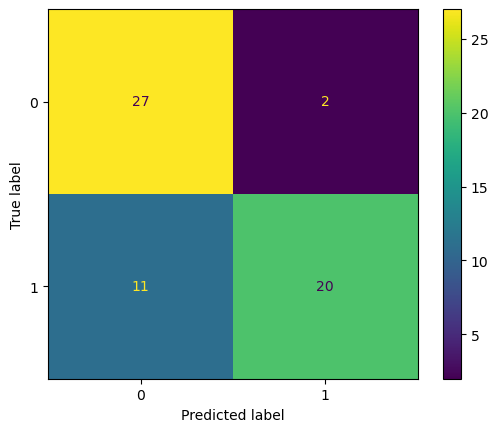

In [21]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay

# TODO
cm=confusion_matrix(y_test,y_pred)
print(cm)
ConfusionMatrixDisplay(cm).plot()
plt.show()

## Practice 1C — Extract TN, FP, FN, TP

In [22]:
# TODO
tn,fp,fn,tp=cm.ravel()

print("TN:",tn)
print("FP:",fp)
print("FN:",fn)
print("TP:",tp)

TN: 27
FP: 2
FN: 11
TP: 20


---
# 2. Accuracy and Error Rate

$$Accuracy=\frac{TP+TN}{N}$$

$$Error\ Rate=1-Accuracy$$

Accuracy asks: **What proportion of all observations did we classify correctly?**

In [23]:
from sklearn.metrics import accuracy_score

# TODO
accuracy=accuracy_score(y_test,y_pred)
error_rate=1 - accuracy

print("Accuracy:",accuracy)
print("Error rate:",error_rate)

Accuracy: 0.7833333333333333
Error rate: 0.21666666666666667


---
# 3. Recall / Sensitivity

$$Recall=\frac{TP}{TP+FN}$$

Of all actual positives, what proportion did we detect?

For fraud:

> Of all fraudulent transactions, what proportion did the model identify?

In [24]:
from sklearn.metrics import recall_score

# TODO
recall=recall_score(y_test,y_pred)
print("Recall:",recall)

Recall: 0.6451612903225806


---
# 4. Specificity

$$Specificity=\frac{TN}{TN+FP}$$

Of all actual negatives, what proportion did we correctly identify?

For fraud:

> Of all legitimate transactions, what proportion did we correctly leave as legitimate?

In [25]:
# TODO
## there is no specificity in sklearn
specificity= tn/(tn+fp)
print("Specificity:",specificity)

Specificity: 0.9310344827586207


---
# 5. Precision

$$Precision=\frac{TP}{TP+FP}$$

Of all observations predicted positive, what proportion really were positive?

For fraud:

> When the model flags a transaction as fraud, how often is it actually fraud?

In [26]:
from sklearn.metrics import precision_score

# TODO
precision=precision_score(y_test,y_pred)
print("Precision:",precision)

Precision: 0.9090909090909091


---
# 6. F1 Score

F1 combines precision and recall using their harmonic mean:

$$F1=2\frac{Precision\times Recall}{Precision+Recall}$$

F1 is useful when both false positives and false negatives matter and the positive class is important.

In [27]:
from sklearn.metrics import f1_score

# TODO
f1=f1_score(y_test,y_pred)
print("F1:",f1)

F1: 0.7547169811320755


## Practice 6A — Build a metric summary

In [28]:
# TODO
metrics_balanced=pd.Series({
    "Accuracy":accuracy,
    "Error Rate":error_rate,
    "Recall":recall,
    "Specificity":specificity,
    "Precision":precision,
    "F1":f1
})
metrics_balanced

Accuracy       0.783333
Error Rate     0.216667
Recall         0.645161
Specificity    0.931034
Precision      0.909091
F1             0.754717
dtype: float64

### Business Decision

Suppose a false negative means failing to detect fraud, while a false positive means temporarily reviewing a legitimate transaction.

Which metric would you emphasize if missing fraud is extremely costly? Why?

**Your response:**  
-

---
# 7. Imbalanced Classification

Now consider a dataset where fraud is rare.

A model that predicts `"not fraud"` for nearly everyone can have high accuracy while being operationally useless.

In [ ]:
imbalanced=pd.read_csv("https://raw.githubusercontent.com/martinwg/ISA591/refs/heads/main/data/fraud_small_imbalanced.csv")

print(imbalanced["is_fraud"].value_counts())
print(imbalanced["is_fraud"].value_counts(normalize=True))

## Practice 7A — The naive classifier

In [ ]:
# Predict every observation as the majority class
y_true=imbalanced["is_fraud"]
y_naive=np.zeros(len(y_true),dtype=int)

# TODO
naive_accuracy=None
naive_recall=None

print("Naive accuracy:",naive_accuracy)
print("Naive recall:",naive_recall)

### Question

Why can the naive classifier have impressive accuracy but terrible business performance?

**Your response:**  
-

## Practice 7B — Fit logistic regression to the imbalanced data

In [ ]:
X=imbalanced.drop(columns=["is_fraud", "cc_num"])
X=pd.get_dummies(X,drop_first=True)
y=imbalanced["is_fraud"]

# TODO: 80/20 split, random_state=591, stratify=y
X_train, X_test, y_train, y_test = None

model=LogisticRegression(max_iter=1000)

# TODO
# model.fit(X_train,y_train)
# y_pred=model.predict(X_test)

## Practice 7C — Balanced accuracy

In [ ]:
from sklearn.metrics import balanced_accuracy_score

# TODO
balanced_acc=None

print("Balanced accuracy:",balanced_acc)

Balanced accuracy averages performance across the two classes:

$$Balanced\ Accuracy=\frac{Sensitivity+Specificity}{2}$$

This prevents the majority class from dominating the score.

## Practice 7D — Compare the important metrics

In [ ]:
# TODO
cm=confusion_matrix(y_test,y_pred)
tn,fp,fn,tp=cm.ravel()
#
summary=pd.Series({
     "Accuracy":accuracy_score(y_test,y_pred),
     "Balanced Accuracy":balanced_accuracy_score(y_test,y_pred),
     "Recall":recall_score(y_test,y_pred),
     "Specificity":tn/(tn+fp),
     "Precision":precision_score(y_test,y_pred,zero_division=0),
     "F1":f1_score(y_test,y_pred,zero_division=0)
})
summary

---
# 8. Metric Choice Depends on the Business Problem

There is no universally best classification metric.

- **Accuracy:** useful when classes/costs are reasonably balanced
- **Recall:** emphasize detecting positives
- **Specificity:** emphasize correctly rejecting negatives
- **Precision:** emphasize trustworthiness of positive alerts
- **F1:** balance precision and recall
- **Balanced accuracy:** useful when classes are imbalanced

The metric should reflect the consequences of FP and FN errors.

## Final Challenge

For each situation, identify the metric you would emphasize and explain why:

1. Cancer screening where missing disease is very costly
2. Spam filter where incorrectly hiding legitimate email is costly
3. Fraud-alert team with limited investigators
4. Balanced manufacturing defect dataset where both errors have similar cost

**Your responses:**  
1.  
2.  
3.  
4.

## Exit Ticket

Why can accuracy be misleading for an imbalanced classification problem?

**Your response:**  
-